# Circular Task Analysis of Self-Generated MouseReMoCo Data

## Objective
This notebook analyses one self-generated circular steering task session recorded with **MouseReMoCo** (task described in Fauviaux et al., 2021).

According to the assignment, the analysis should:
- load the self-generated `data.csv` and `marker.csv`;
- identify the recording periods from the markers;
- reproduce the raw time-series and trajectory figures;
- recompute the table of results (nLaps, Re, Te, error, MT/lap, IDe/lap, Be, IPe) with our own code;
- compare our table with the table written by MouseReMoCo at the end of `marker.csv`.

The session contains **5 recordings**, each separated by a pause.
Only `numpy`, `matplotlib` and `os` are used, as required by the assignment.

## 0. Imports

In [1]:
# imports (this is all we need for this assignment)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
import os

%matplotlib inline

# if the present working directory is the 'notebooks' folder, go to the project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")
print("Working directory:", os.getcwd())

Working directory: c:\Users\user\Documents\IEAP\Circular-task-D


## 1. Load the self-generated files

The expected repository structure is:

```text
Circular-task-D/
├── Shakir_own_data_analysis_FINAL.ipynb
└── data/
    └── shakir-own-data/
        ├── data.csv
        └── marker.csv
```

In [2]:
# File paths
DATA_PATH = os.path.join("data", "shakir-own-data", "data.csv")
MARKER_PATH = os.path.join("data", "shakir-own-data", "marker.csv")

for p in (DATA_PATH, MARKER_PATH):
    if not os.path.exists(p):
        folder = os.path.dirname(p)
        raise FileNotFoundError(f"File not found: {p}. Files in '{folder}': "
                                f"{os.listdir(folder) if os.path.isdir(folder) else 'folder does not exist'}")

print("Data file:", DATA_PATH)
print("Marker file:", MARKER_PATH)
print("Data exists:", os.path.exists(DATA_PATH))
print("Marker exists:", os.path.exists(MARKER_PATH))

# constant used to compute the effective width: Te = 4.133 x standard deviation of the radius
K_WIDTH = 4.133

Data file: data\shakir-own-data\data.csv
Marker file: data\shakir-own-data\marker.csv
Data exists: True
Marker exists: True


## 2. Read and inspect `data.csv`

**How the file is organised** (the most important point of the assignment):

* The first line is the **header**: screen size, centre of the circle, radius of the task, tolerance of the task, etc.
* Then the column names: `timestamp, mouseX, mouseY, mouseInTarget`.
* Then one line per mouse sample. `timestamp` is in milliseconds (since 1 January 1970). `mouseInTarget` is 1 if the cursor is inside the yellow ring and 0 if it is outside.
* The mouse position is in **screen pixels**: the origin is the top-left corner of the screen and `y` goes **down**.
* The file also contains the samples recorded **during the pauses**. They must be removed later.

In [3]:
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw_lines = f.read().splitlines()

# 1) find the line with the column names
header_idx = None
for i, line in enumerate(raw_lines):
    if line.strip().replace(" ", "").lower().startswith("timestamp,mousex,mousey"):
        header_idx = i
        break
if header_idx is None:
    raise ValueError("Could not find the 'timestamp,mouseX,mouseY' line in data.csv")

# 2) read the header information (key value;key value;...)
header = {}
for line in raw_lines[:header_idx]:
    for token in line.split(";"):
        token = token.strip()
        if token == "" or not token[0].isalpha():
            continue                      # skip empty parts and the date line
        parts = token.split(None, 1)      # split at the first space
        if len(parts) < 2:
            continue
        try:
            header[parts[0]] = float(parts[1])
        except ValueError:
            header[parts[0]] = parts[1]

print(f"Header line information in '{DATA_PATH}':")
for key, value in header.items():
    print(f"  {key}: {value}")

# 3) read the numbers
data = np.genfromtxt(DATA_PATH, delimiter=",", skip_header=header_idx + 1)
data = data[~np.isnan(data[:, :3]).any(axis=1)]    # remove lines with missing values

print("\nNumber of samples:", len(data))
print("First timestamp:", int(data[0, 0]))
print("Last timestamp:", int(data[-1, 0]))
print("\nFirst 5 samples (timestamp, mouseX, mouseY, mouseInTarget):")
print(data[:5])

Header line information in 'data\shakir-own-data\data.csv':
  software: mouseReMoCo
  version: 1.3.0
  isWithLSL: false
  screenWidth: 1902.0
  screenHeight: 973.0
  centerX: 951.0
  centerY: 486.0
  autoStart: 3600.0
  cycleMaxNumber: 6.0
  cycleDuration: 20.0
  borderColor: java.awt.Color[r=255,g=255,b=255]
  textColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  task: circular
  cornerX: 545.0
  cornerY: 80.0
  externalRadius: 406.0
  internalRadius: 326.0
  borderRadius: 1.0
  cursorRadius: 16.0
  indexOfDifficulty: 48.86179212285402
  taskRadius: 365.5
  taskTolerance: 47.0

Number of samples: 13290
First timestamp: 1794746092178
Last timestamp: 1794746271997

First 5 samples (timestamp, mouseX, mouseY, mouseInTarget):
[[1.79474609e+12 6.06000000e+02 3.56000000e+02 1.00000000e+00]
 [1.79474609e+12 6.05000000e+02 3.59000000e+02 1.00000000e+00]

## 3. Read and inspect `marker.csv`

`marker.csv` contains event markers. Each active recording starts with `DoCycleChange:DoRecord` and ends with `DoCycleChange:DoPause`.
The timestamp is the **second comma-separated field** of each marker line.
At the end of the file, MouseReMoCo wrote its own table of results. We read it to compare it with our results later.

In [4]:
with open(MARKER_PATH, "r", encoding="utf-8") as f:
    marker_lines = f.read().splitlines()

markers = []            # list of (timestamp in ms, text)
software_table = {}     # table written by MouseReMoCo: name -> list of numbers

for line in marker_lines[1:]:                 # line 0 is the header
    parts = line.split(",", 2)
    # marker line:  date , timestamp (13 digits) , text
    if len(parts) == 3 and parts[1].strip().isdigit() and len(parts[1].strip()) == 13:
        markers.append((int(parts[1].strip()), parts[2].strip()))
    # table line:  ' Rec001 ,  5.40 ,  351.90 , ...'
    elif line.strip().startswith(("Theory", "Rec")):
        cols = [c.strip() for c in line.split(",")]
        if cols[-1] == "":
            cols = cols[:-1]                  # the line ends with a comma
        values = []
        for c in cols[1:]:
            try:
                values.append(float(c))
            except ValueError:
                values.append(np.nan)
        software_table[cols[0]] = values

print("Markers:\n")
for t, text in markers:
    print(f"{t}: {text}")

Markers:

1794746091275: KeyTyped=32 ASCI=  DoCycleChange
1794746091275: DoCycleChange:DoStartCycleTimedSequence
1794746091275: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1794746111291: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1794746131300: DoCycleChange:DoRecord RecordDone=1 PauseDone=1 ToDo=6
1794746151310: DoCycleChange:DoPause RecordDone=2 PauseDone=1 ToDo=6
1794746171313: DoCycleChange:DoRecord RecordDone=2 PauseDone=2 ToDo=6
1794746191314: DoCycleChange:DoPause RecordDone=3 PauseDone=2 ToDo=6
1794746211321: DoCycleChange:DoRecord RecordDone=3 PauseDone=3 ToDo=6
1794746231328: DoCycleChange:DoPause RecordDone=4 PauseDone=3 ToDo=6
1794746251340: DoCycleChange:DoRecord RecordDone=4 PauseDone=4 ToDo=6
1794746271343: DoCycleChange:DoPause RecordDone=5 PauseDone=4 ToDo=6
1794746272972: KeyTyped=81 ASCI=Q WINDOW_CLOSING
1794746272972: 


## 4. Extract the 5 recording intervals

Each `DoRecord` timestamp is paired with the next `DoPause` timestamp. These intervals are used to select the samples of `data.csv` that belong to a recording.

In [5]:
record_starts = [t for t, text in markers if "DoCycleChange:DoRecord" in text]
record_ends = [t for t, text in markers if "DoCycleChange:DoPause" in text]

print("Record starts:", record_starts)
print("Record ends:", record_ends)

if len(record_starts) != len(record_ends):
    raise ValueError(f"Different numbers of starts ({len(record_starts)}) and ends ({len(record_ends)}).")
if len(record_starts) == 0:
    raise ValueError("No recording intervals were detected.")

print("\nNumber of detected recordings:", len(record_starts))

t0 = record_starts[0]    # time zero = first DoRecord marker
print("\nrecord times (seconds since the first DoRecord marker):")
for s, e in zip(record_starts, record_ends):
    print(f"{(s - t0) / 1000:>8.3f} to {(e - t0) / 1000:>8.3f} ({(e - s) / 1000:.3f} s)")

Record starts: [1794746091275, 1794746131300, 1794746171313, 1794746211321, 1794746251340]
Record ends: [1794746111291, 1794746151310, 1794746191314, 1794746231328, 1794746271343]

Number of detected recordings: 5

record times (seconds since the first DoRecord marker):
   0.000 to   20.016 (20.016 s)
  40.025 to   60.035 (20.010 s)
  80.038 to  100.039 (20.001 s)
 120.046 to  140.053 (20.007 s)
 160.065 to  180.068 (20.003 s)


## 5. Split the raw data into recordings

The samples are selected with the marker timestamps. The samples recorded during the pauses are not used.

**Coordinates.** We put the origin at the centre of the circle (`x = mouseX - centerX`) and we turn the y axis upwards (`y = -(mouseY - centerY)`), like in a normal graph.
The centre of the circle (`centerX`, `centerY`) comes from the header of `data.csv`.
Time is in seconds since the first `DoRecord` marker.

In [6]:
center_x = header["centerX"]
center_y = header["centerY"]
task_radius = header["taskRadius"]
task_tolerance = header["taskTolerance"]

print(f"Centre of the circle: ({center_x:.0f}, {center_y:.0f}) pixels")
print(f"Task radius: {task_radius} pixels")
print(f"Task tolerance: {task_tolerance} pixels\n")

records = []
for start, end in zip(record_starts, record_ends):
    keep = (data[:, 0] >= start) & (data[:, 0] <= end)
    d = data[keep]
    records.append(dict(
        t=(d[:, 0] - t0) / 1000.0,         # time (s) since the first DoRecord
        x=d[:, 1] - center_x,              # centred x
        y=-(d[:, 2] - center_y),           # centred y, axis upwards
        inside=d[:, 3],                    # 1 = inside the ring, 0 = outside
        start=(start - t0) / 1000.0,
        end=(end - t0) / 1000.0,
    ))

print("Number of records:", len(records))
for i, rec in enumerate(records):
    n = len(rec["t"])
    duration = rec["t"][-1] - rec["t"][0]
    print(f"record {i}: {n} samples from {rec['t'][0]:>7.3f} to {rec['t'][-1]:>7.3f} s, "
          f"({duration:.3f}s, {(n - 1) / duration:.3f} Hz)")

# stop early if a recording is empty
empty = [i for i, r in enumerate(records) if len(r["t"]) == 0]
if empty:
    raise ValueError(f"These recordings are empty: {empty}")

# check: is the flag 'mouseInTarget' the same as the geometry (inside the ring)?
same = True
for rec in records:
    r = np.hypot(rec["x"], rec["y"])
    geometry = (np.abs(r - task_radius) <= task_tolerance / 2).astype(float)
    if np.any(geometry != rec["inside"]):
        same = False
print("\nmouseInTarget equals the geometric test |r - taskRadius| <= tolerance/2:", same)

Centre of the circle: (951, 486) pixels
Task radius: 365.5 pixels
Task tolerance: 47.0 pixels

Number of records: 5
record 0: 2377 samples from   0.903 to  20.016 s, (19.113s, 124.313 Hz)
record 1: 2383 samples from  40.540 to  60.035 s, (19.495s, 122.185 Hz)
record 2: 2349 samples from  80.249 to 100.039 s, (19.790s, 118.646 Hz)
record 3: 2261 samples from 120.373 to 140.042 s, (19.669s, 114.902 Hz)
record 4: 2322 samples from 160.069 to 179.792 s, (19.723s, 117.680 Hz)

mouseInTarget equals the geometric test |r - taskRadius| <= tolerance/2: True


## 6. Raw X and Y time series (all records)

Black dashed line = start of a record, red dashed line = end of a record.

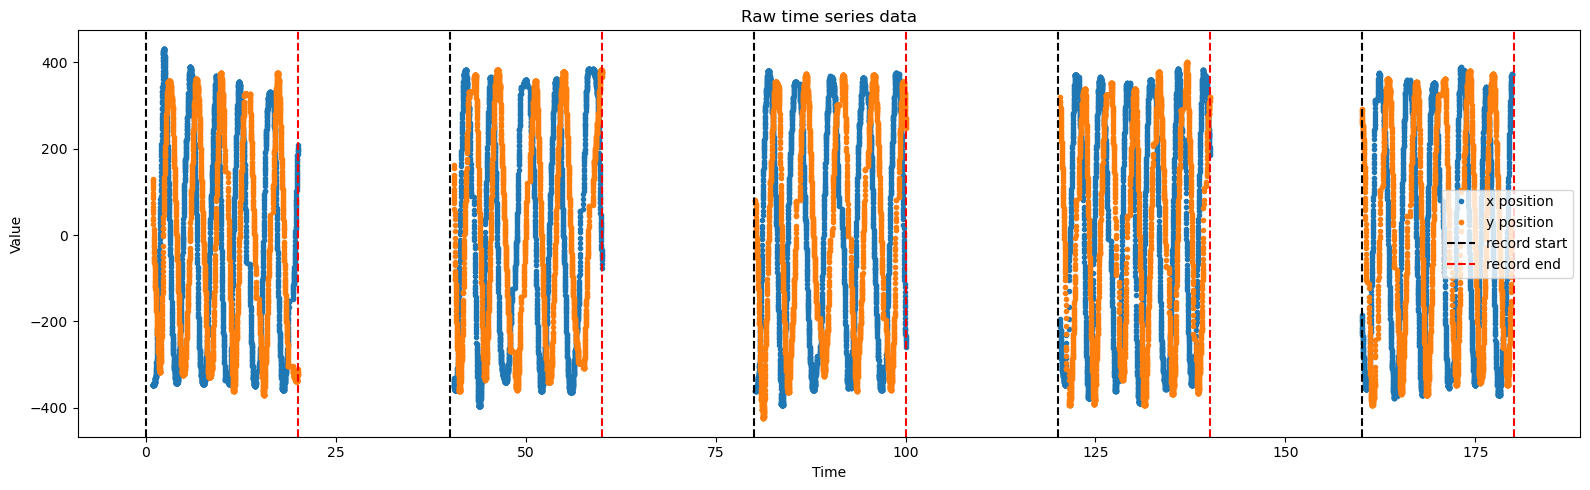

In [7]:
fig, ax = plt.subplots(figsize=(16, 5))
for i, rec in enumerate(records):
    ax.plot(rec["t"], rec["x"], ".", color="tab:blue", label="x position" if i == 0 else None)
    ax.plot(rec["t"], rec["y"], ".", color="tab:orange", label="y position" if i == 0 else None)
    ax.axvline(rec["start"], color="black", linestyle="--", label="record start" if i == 0 else None)
    ax.axvline(rec["end"], color="red", linestyle="--", label="record end" if i == 0 else None)
ax.set_title("Raw time series data")
ax.set_xlabel("Time")
ax.set_ylabel("Value")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Raw trajectory of all records

The red circles are the two edges of the target ring (radius ± tolerance / 2). Green dots are the samples inside the target.

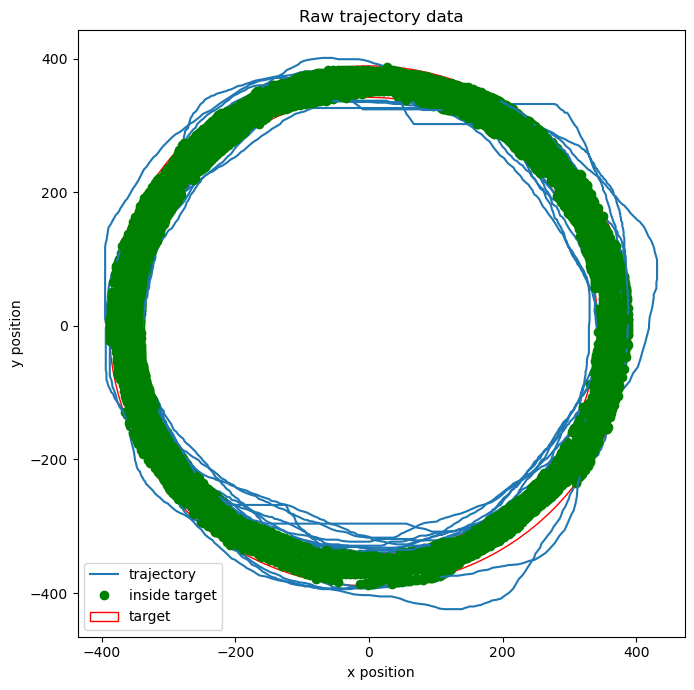

In [8]:
fig, ax = plt.subplots(figsize=(8, 7))
for i, rec in enumerate(records):
    ax.plot(rec["x"], rec["y"], color="tab:blue", label="trajectory" if i == 0 else None)
    ins = rec["inside"] == 1
    ax.plot(rec["x"][ins], rec["y"][ins], "o", color="green", label="inside target" if i == 0 else None)

ax.add_patch(Circle((0, 0), task_radius + task_tolerance / 2, fill=False, edgecolor="red"))
ax.add_patch(Circle((0, 0), task_radius - task_tolerance / 2, fill=False, edgecolor="red"))

handles, labels = ax.get_legend_handles_labels()
handles.append(Rectangle((0, 0), 1, 1, fill=False, edgecolor="red"))
labels.append("target")
ax.legend(handles, labels)
ax.set_title("Raw trajectory data")
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 8. Recompute the statistics from the raw data

The calculations are done separately for each recording. Let `r` be the distance between the cursor and the centre of the circle.

| Name | Meaning | How we compute it |
|---|---|---|
| **nLaps** | number of laps | total change of the (unwrapped) angle divided by 2π |
| **Re** | effective radius (pixel) | mean of `r` |
| **Te** | effective tolerance (pixel) | `4.133 × standard deviation of r` |
| **error** | % of samples outside the ring | `100 × (1 − mean(mouseInTarget))` |
| **MT/lap** | movement time per lap (s) | duration of the record / `abs(nLaps)` |
| **IDe/lap** | effective index of difficulty | `2π × Re / Te` |
| **Be** | accuracy ratio | `Te / taskTolerance` (1 = as accurate as the task asks) |
| **IPe** | effective throughput (bit/s) | `IDe/lap / MT/lap` |

The **Theory** row uses the task values: `Re = taskRadius`, `Te = taskTolerance`, `Be = 1`. Its error is the error expected from a normal distribution when `Te = 4.133 × SD` (the band is ± 2.0665 SD wide).

In [9]:
def erfc_approx(x):
    # Complementary error function (Abramowitz-Stegun 7.1.26, precision about 1e-7).
    # Written by hand because we are not allowed to import scipy or math.
    z = abs(x)
    t = 1.0 / (1.0 + 0.3275911 * z)
    poly = t * (0.254829592 + t * (-0.284496736 + t * (1.421413741 + t * (-1.453152027 + t * 1.061405429))))
    return poly * np.exp(-z * z)


def circular_statistics(rec, tolerance):
    x, y, t, inside = rec["x"], rec["y"], rec["t"], rec["inside"]
    r = np.hypot(x, y)                                  # distance to the centre

    angle = np.unwrap(np.arctan2(y, x))                 # angle without jumps
    n_laps = (angle[-1] - angle[0]) / (2 * np.pi)

    Re = np.mean(r)
    Te = K_WIDTH * np.std(r, ddof=1)
    error = 100.0 * (1.0 - np.mean(inside))
    MT = (t[-1] - t[0]) / abs(n_laps)
    IDe = 2 * np.pi * Re / Te
    Be = Te / tolerance
    IPe = IDe / MT
    return [n_laps, Re, Te, error, MT, IDe, Be, IPe]


statistics = [circular_statistics(rec, task_tolerance) for rec in records]
theory_error = 100.0 * erfc_approx((K_WIDTH / 2) / np.sqrt(2.0))

print("recomputed statistics for all records:")
print("    Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,")
print("   unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,")
print(f" Theory ,{1:>6.2f} ,{task_radius:>8.2f} ,{task_tolerance:>8.2f} ,{theory_error:>8.2f} ,"
      f"{'':>8} ,{'':>8} ,{1:>8.2f} ,{'':>8} ,")
for i, s in enumerate(statistics, start=1):
    print(f" Rec{i:03d} ,{s[0]:>6.2f} ,{s[1]:>8.2f} ,{s[2]:>8.2f} ,{s[3]:>8.2f} ,"
          f"{s[4]:>8.2f} ,{s[5]:>8.2f} ,{s[6]:>8.2f} ,{s[7]:>8.2f} ,")

recomputed statistics for all records:
    Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
   unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,
 Theory ,  1.00 ,  365.50 ,   47.00 ,    3.88 ,         ,         ,    1.00 ,         ,
 Rec001 ,  5.40 ,  351.91 ,   90.81 ,   36.90 ,    3.54 ,   24.35 ,    1.93 ,    6.88 ,
 Rec002 ,  4.85 ,  363.78 ,  104.00 ,   33.07 ,    4.02 ,   21.98 ,    2.21 ,    5.47 ,
 Rec003 ,  4.91 ,  361.33 ,   87.20 ,   21.07 ,    4.03 ,   26.04 ,    1.86 ,    6.46 ,
 Rec004 ,  5.83 ,  365.50 ,   67.66 ,   17.51 ,    3.37 ,   33.94 ,    1.44 ,   10.06 ,
 Rec005 ,  5.67 ,  362.65 ,   65.62 ,   12.23 ,    3.48 ,   34.72 ,    1.40 ,    9.99 ,


## 9. Comparison with the table written by MouseReMoCo

The software wrote its own table at the end of `marker.csv`. Here we put the two tables side by side and compute the difference (our code − software).

In [10]:
print("Table written by MouseReMoCo at the end of marker.csv:")
print("    Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,")
for name, vals in software_table.items():
    vals = list(vals) + [np.nan] * (8 - len(vals))
    print(f" {name:>6} ," + ",".join(f"{v:>8.2f} " if not np.isnan(v) else f"{'':>8} " for v in vals))

print("\nDifference (our code - MouseReMoCo):")
print("    Var ,  nLaps ,     Re ,     Te ,  error , MT/lap , IDe/lap ,     Be ,    IPe")
for i, s in enumerate(statistics, start=1):
    name = f"Rec{i:03d}"
    if name in software_table:
        diff = [a - b for a, b in zip(s, software_table[name])]
        print(f" {name} ," + ",".join(f"{d:>8.2f}" for d in diff))

Table written by MouseReMoCo at the end of marker.csv:
    Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
 Theory ,    1.00 ,  365.50 ,   47.00 ,    3.88 ,         ,         ,    1.00 ,         
 Rec001 ,    5.40 ,  351.90 ,   90.80 ,   39.88 ,    3.54 ,   24.35 ,    1.93 ,    6.88 
 Rec002 ,    4.85 ,  363.77 ,  104.01 ,   30.92 ,    4.02 ,   21.97 ,    2.21 ,    5.47 
 Rec003 ,    4.91 ,  361.33 ,   87.23 ,   22.35 ,    4.03 ,   26.03 ,    1.86 ,    6.45 
 Rec004 ,    5.83 ,  365.50 ,   67.65 ,   16.77 ,    3.37 ,   33.95 ,    1.44 ,   10.06 
 Rec005 ,    5.67 ,  362.65 ,   65.62 ,   13.06 ,    3.48 ,   34.72 ,    1.40 ,    9.99 

Difference (our code - MouseReMoCo):
    Var ,  nLaps ,     Re ,     Te ,  error , MT/lap , IDe/lap ,     Be ,    IPe
 Rec001 ,    0.00,    0.01,    0.01,   -2.98,   -0.00,   -0.00,    0.00,    0.00
 Rec002 ,    0.00,    0.01,   -0.01,    2.15,   -0.00,    0.01,    0.00,    0.00
 Rec003 ,    0.00,   -0.00,   -0.03,   -1.

## 10. Analyse and visualise each recording separately

For each of the 5 recordings, two figures are produced.

1. **Trajectory**: the screen (magenta rectangle), the yellow target ring, the samples inside the ring (green) and outside the ring (red).
2. **Time series**: X position, Y position and `mouseInTarget` over time (time in seconds since the first `DoRecord` marker).

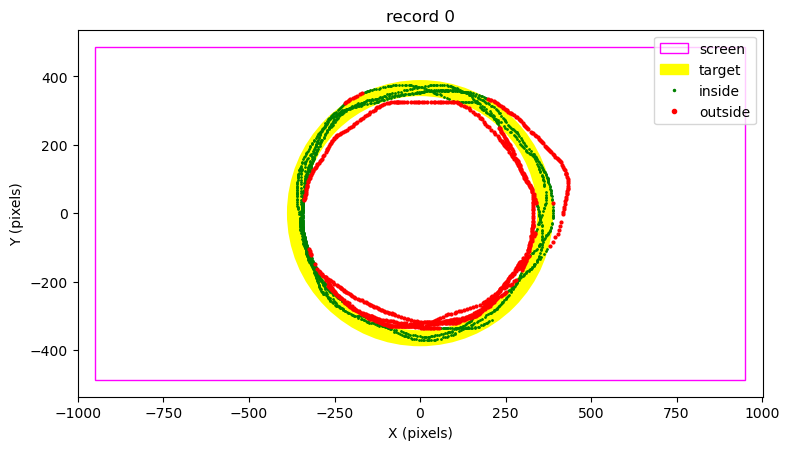

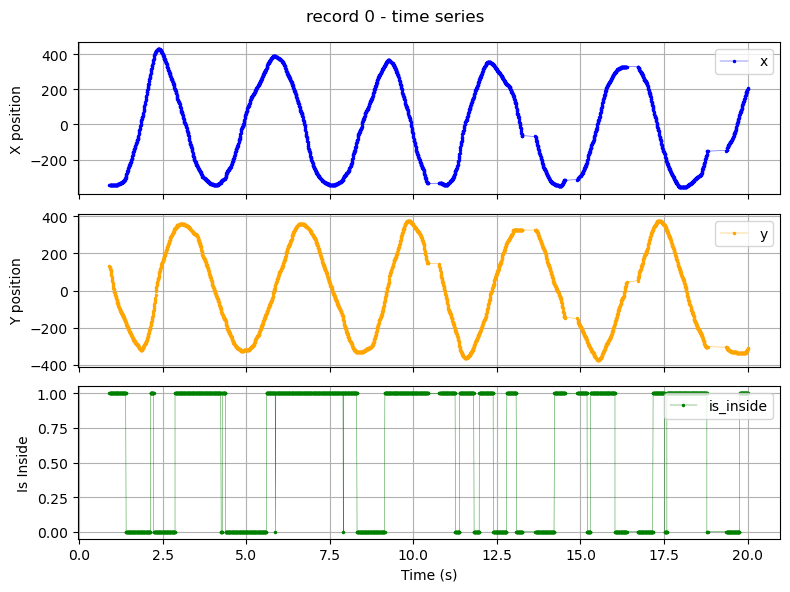

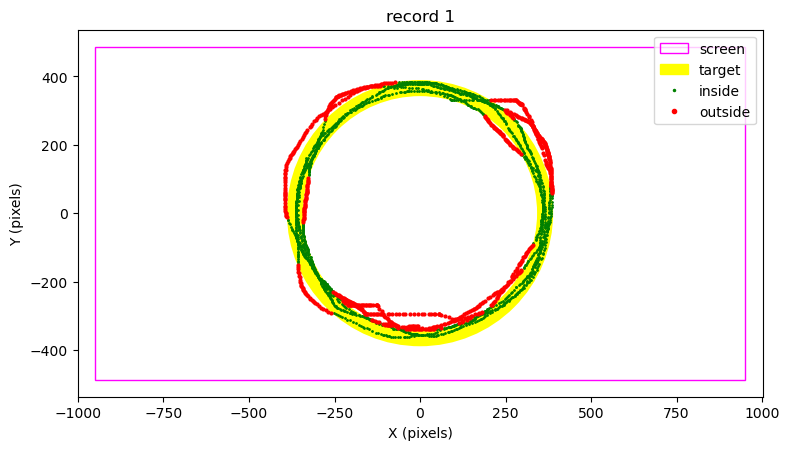

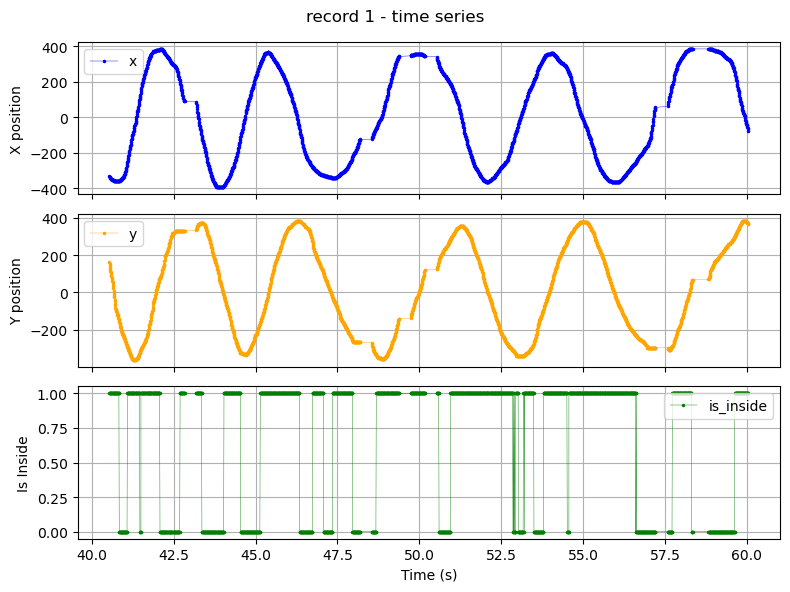

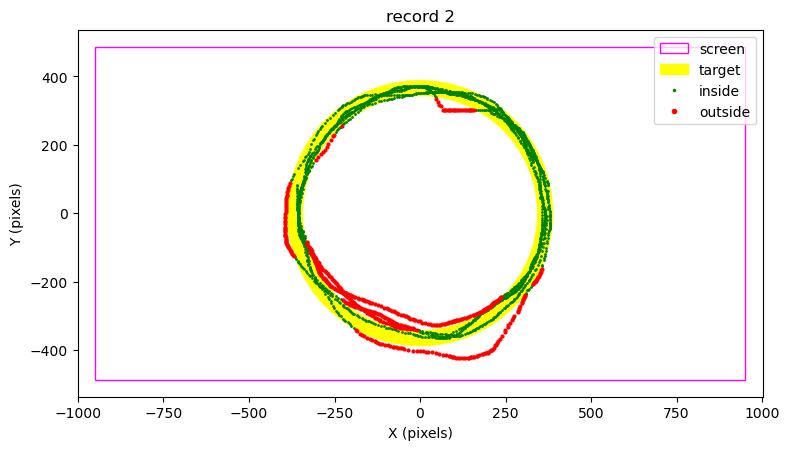

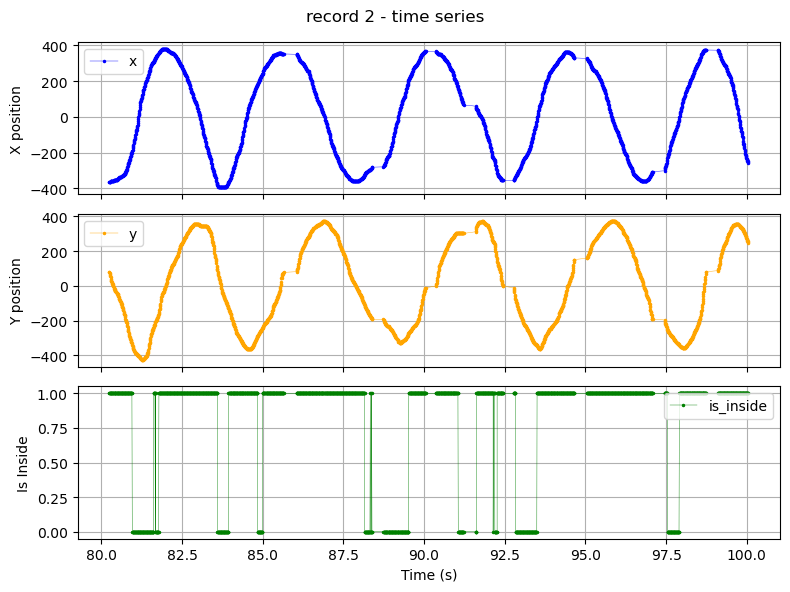

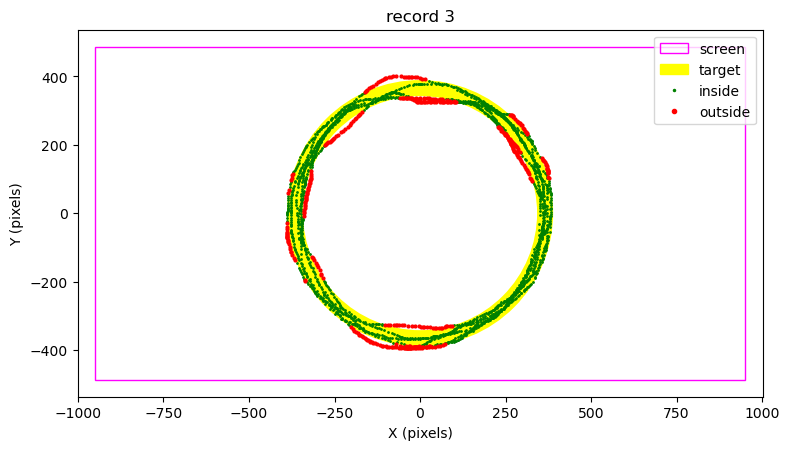

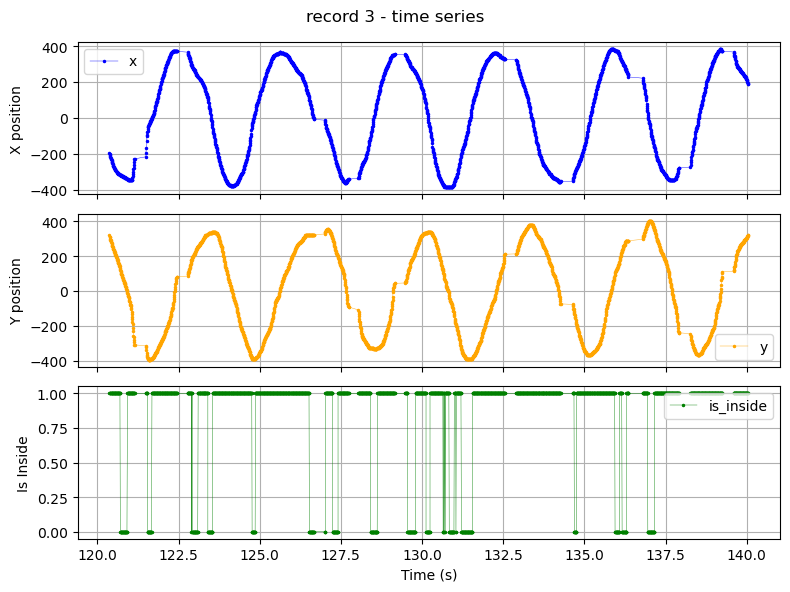

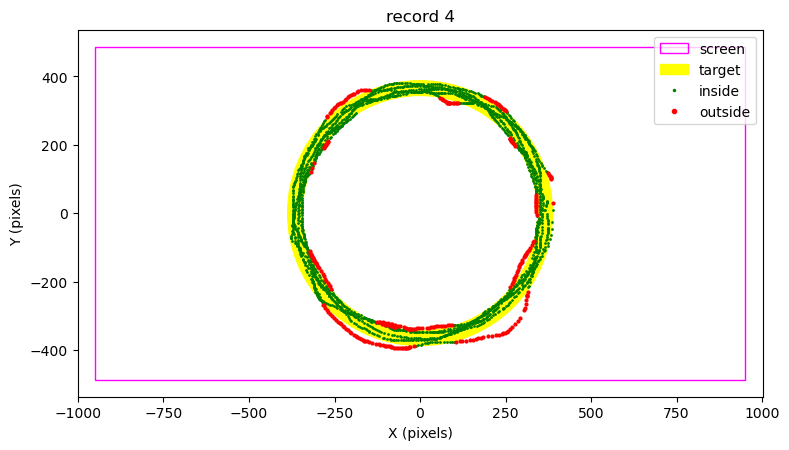

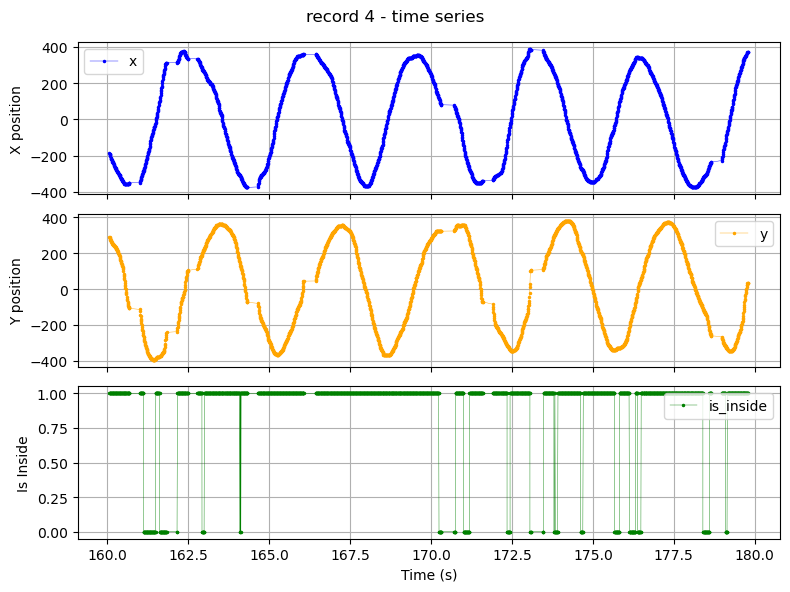

In [11]:
screen_w, screen_h = header["screenWidth"], header["screenHeight"]

for i, rec in enumerate(records):
    # ---------- trajectory ----------
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.add_patch(Rectangle((-screen_w / 2, -screen_h / 2), screen_w, screen_h, fill=False, edgecolor="magenta"))
    ax.add_patch(Circle((0, 0), task_radius + task_tolerance / 2, facecolor="yellow", edgecolor="none", zorder=1))
    ax.add_patch(Circle((0, 0), task_radius - task_tolerance / 2, facecolor="white", edgecolor="none", zorder=2))
    ins = rec["inside"] == 1
    ax.plot(rec["x"][ins], rec["y"][ins], ".", color="green", markersize=2, zorder=3)
    ax.plot(rec["x"][~ins], rec["y"][~ins], ".", color="red", markersize=4, zorder=3)
    handles = [Rectangle((0, 0), 1, 1, fill=False, edgecolor="magenta"),
               Rectangle((0, 0), 1, 1, facecolor="yellow", edgecolor="yellow"),
               plt.Line2D([], [], marker=".", color="green", linestyle="", markersize=3),
               plt.Line2D([], [], marker=".", color="red", linestyle="", markersize=6)]
    ax.legend(handles, ["screen", "target", "inside", "outside"], loc="upper right")
    ax.set_xlim(-screen_w / 2 - 50, screen_w / 2 + 50)
    ax.set_ylim(-screen_h / 2 - 50, screen_h / 2 + 50)
    ax.set_aspect("equal")
    ax.set_title(f"record {i}")
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")
    plt.tight_layout()
    plt.show()

    # ---------- time series ----------
    fig, axs = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
    axs[0].plot(rec["t"], rec["x"], ".-", color="blue", linewidth=0.3, markersize=3, label="x")
    axs[0].set_ylabel("X position")
    axs[1].plot(rec["t"], rec["y"], ".-", color="orange", linewidth=0.3, markersize=3, label="y")
    axs[1].set_ylabel("Y position")
    axs[2].plot(rec["t"], rec["inside"], ".-", color="green", linewidth=0.3, markersize=3, label="is_inside")
    axs[2].set_ylabel("Is Inside")
    axs[2].set_xlabel("Time (s)")
    for a in axs:
        a.grid(True)
        a.legend()
    fig.suptitle(f"record {i} - time series")
    plt.tight_layout()
    plt.show()

## 11. Summary and interpretation

**What was done.** The self-generated session was split into its 5 recordings with the markers of MouseReMoCo. The centre, the radius and the tolerance of the task were read from the header of `data.csv`. The statistics were recomputed with our own code (only `numpy`, `matplotlib` and `os`).

**Comparison with the software table.** For my data:

| Column | Result |
|---|---|
| nLaps, Re, Te, MT/lap, IDe/lap, Be, IPe | Same as the software table (differences of 0.03 or less, which is a rounding-size difference) |
| error (%) | Different: ours 36.90 / 33.07 / 21.07 / 17.51 / 12.23, software 39.88 / 30.92 / 22.35 / 16.77 / 13.06 |

Our error is the percentage of samples with `mouseInTarget = 0`, and this flag is identical to the geometric test (|r − taskRadius| ≤ tolerance / 2). I could not find the exact definition used by the software for this column. The other seven columns agree, so the difference is limited to how the software counts the error.

**Interpretation of the performance.**
- `Be` is above 1 in all records (between 1.40 and 2.21): the cursor was less accurate than the task tolerance (47 pixels).
- `Be` is lower in the last two records (1.44 and 1.40) than in the first three (1.93, 2.21, 1.86), and `IPe` is higher (10.06 and 9.99 bit/s against 6.88, 5.47 and 6.46 bit/s): accuracy and throughput were better at the end of the session.
- In record 0, many red points are on the inner side of the ring (cursor too close to the centre). This agrees with `Re` = 351.9 pixels, smaller than the task radius of 365.5 pixels.

**Sign of nLaps.** With the y axis upwards, nLaps is positive, like in the MouseReMoCo table.

### Files analysed
- `data/shakir-own-data/data.csv`
- `data/shakir-own-data/marker.csv`